# ARTIFICIAL NEURAL NETWORK (ANN)

## Project - Fashion MNIST

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [2]:
data = pd.read_csv('Downloads/Fashion MNIST Files/fashion_mnist.csv')

In [3]:
data.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
data.columns

Index(['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779', 'pixel780',
       'pixel781', 'pixel782', 'pixel783', 'pixel784'],
      dtype='object', length=785)

In [5]:
data.shape

(60000, 785)

In [6]:
X = data.drop(columns = ['label'])
y = data['label']

In [7]:
X

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,5,0,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,1,2,0,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,0,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,0,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
y

0        2
1        9
2        6
3        0
4        3
        ..
59995    9
59996    1
59997    8
59998    8
59999    7
Name: label, Length: 60000, dtype: int64

In [9]:
X.shape

(60000, 784)

In [10]:
y.shape

(60000,)

In [11]:
X = X.values.reshape((len(X),28,28,1))

In [12]:
X.shape

(60000, 28, 28, 1)

In [13]:
X = X/255

In [14]:
X

array([[[[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [0.        ],
         [0.        ]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [0.        ],
         [0.        ]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [0.        ],
         [0.        ]],

        ...,

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [0.        ],
         [0.        ]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [0.        ],
         [0.        ]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [0.        ],
         [0.        ]]],


       [[[0.        ],
         [0.        ],
         [0.  

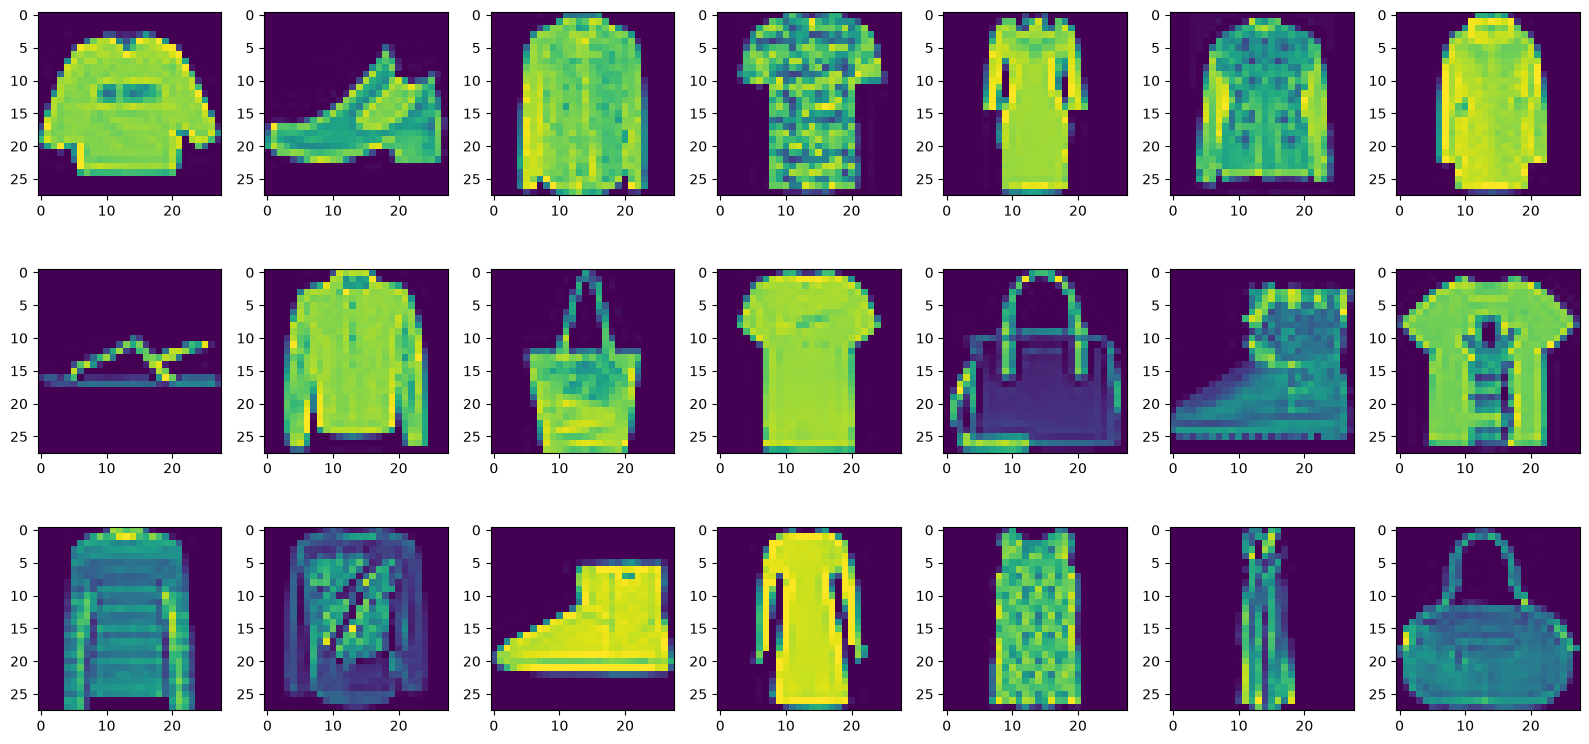

In [15]:
plt.figure(figsize = (16,8))
for i in range(21):
    plt.subplot(3,7,i+1)
    plt.imshow(X[i])
plt.tight_layout()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2)

In [17]:
X_train.shape

(48000, 28, 28, 1)

In [18]:
X_test.shape

(12000, 28, 28, 1)

In [19]:
model = keras.Sequential([
                  keras.layers.Flatten(input_shape = (28,28)),
                  keras.layers.Dense(100, activation="relu"),
                  keras.layers.Dense(100, activation="relu"),
                  keras.layers.Dense(10,activation="sigmoid")
])

C:\Users\varsh\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy',metrics = ['accuracy'])

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 100)                 │          10,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 89,610 (350.04 KB)

 Trainable params: 89,610 (350.04 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.fit(X_train,y_train, epochs = 10, validation_split=0.05, batch_size = 20)

Epoch 1/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8911 - loss: 0.2891 - val_accuracy: 0.8525 - val_loss: 0.3981
Epoch 2/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8977 - loss: 0.2743 - val_accuracy: 0.8775 - val_loss: 0.3309
Epoch 3/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9005 - loss: 0.2657 - val_accuracy: 0.8687 - val_loss: 0.3674
Epoch 4/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9041 - loss: 0.2545 - val_accuracy: 0.8729 - val_loss: 0.3582
Epoch 5/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9067 - loss: 0.2453 - val_accuracy: 0.8662 - val_loss: 0.3602
Epoch 6/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9099 - loss: 0.2381 - val_accuracy: 0.8817 - val_loss: 0.3629
Epoch 7/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9125 - loss: 0.2297 - val_accuracy: 0.8796 - val_loss: 0.3858
Epoch 8/10
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9149 - loss: 0

In [24]:
model.evaluate(X_train, y_train)

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9198 - loss: 0.2098


[0.2098083347082138, 0.9198125004768372]

In [25]:
prediction = model.predict(X_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [26]:
prediction

array([[5.4517876e-08, 5.2266319e-06, 7.0040663e-08, ..., 9.7424644e-01,
        6.4991323e-06, 1.0501156e-04],
       [9.9951375e-01, 1.4400141e-05, 1.7397178e-02, ..., 3.8699793e-10,
        1.0457421e-05, 2.3996287e-09],
       [7.8437421e-03, 4.4061104e-05, 9.9988580e-01, ..., 4.0118249e-11,
        5.8485218e-04, 1.4405769e-15],
       ...,
       [8.2712775e-01, 6.3319961e-03, 4.4117817e-01, ..., 6.3767366e-06,
        4.1040201e-03, 9.1260172e-06],
       [4.2993702e-09, 3.4182982e-12, 2.2405724e-09, ..., 1.3176286e-06,
        2.5462214e-07, 7.6547839e-13],
       [2.8434478e-02, 2.4034615e-04, 8.4880406e-01, ..., 3.7003197e-06,
        1.7612266e-03, 1.1307224e-06]], shape=(12000, 10), dtype=float32)

In [42]:
labels = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle Boot'
}

In [43]:
labels

{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle Boot'}

In [44]:
np.argmax(prediction[0])

np.int64(7)

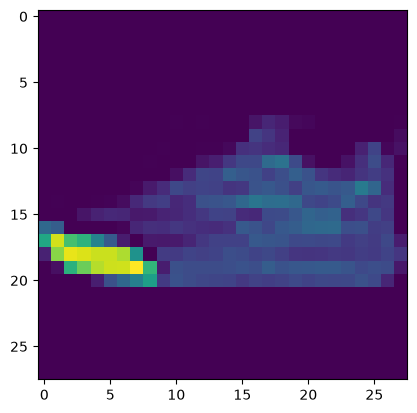

In [45]:
plt.imshow(X_test[0])

In [46]:
predicted_values = [int(np.argmax(i)) for i in prediction]

In [47]:
print(predicted_values)

[7, 0, 2, 8, 0, 5, 6, 7, 3, 3, 2, 2, 0, 7, 7, 8, 7, 0, 8, 0, 6, 4, 9, 0, 9, 9, 9, 2, 5, 4, 8, 4, 3, 0, 3, 1, 7, 8, 9, 8, 3, 5, 1, 8, 9, 1, 1, 7, 3, 9, 2, 2, 4, 7, 8, 1, 0, 4, 1, 2, 6, 0, 8, 6, 0, 3, 5, 5, 3, 5, 1, 3, 3, 2, 4, 8, 2, 1, 0, 4, 3, 8, 1, 8, 8, 7, 7, 6, 4, 8, 3, 7, 0, 9, 8, 5, 0, 5, 9, 7, 8, 0, 6, 3, 2, 5, 3, 4, 0, 9, 7, 8, 3, 8, 8, 8, 4, 4, 6, 4, 9, 3, 4, 3, 8, 0, 5, 3, 3, 0, 3, 1, 1, 0, 6, 6, 1, 9, 5, 0, 4, 8, 8, 5, 0, 5, 7, 7, 2, 3, 0, 3, 2, 8, 3, 2, 2, 2, 5, 0, 5, 0, 2, 1, 5, 8, 7, 9, 5, 9, 2, 0, 1, 4, 9, 2, 7, 3, 0, 4, 3, 4, 0, 2, 2, 9, 3, 4, 4, 1, 8, 1, 6, 4, 9, 2, 8, 0, 1, 4, 8, 0, 1, 4, 4, 2, 8, 1, 0, 2, 1, 7, 1, 5, 2, 9, 1, 4, 9, 2, 8, 0, 3, 2, 4, 0, 1, 4, 0, 1, 2, 5, 1, 8, 2, 4, 2, 1, 5, 3, 9, 9, 1, 0, 5, 2, 3, 5, 7, 2, 2, 6, 4, 2, 4, 8, 8, 9, 8, 8, 0, 0, 6, 9, 8, 8, 8, 5, 4, 9, 0, 5, 1, 6, 0, 6, 1, 7, 6, 7, 4, 3, 8, 1, 6, 1, 2, 4, 5, 9, 5, 8, 4, 3, 9, 8, 9, 4, 3, 9, 2, 5, 9, 8, 5, 8, 7, 2, 6, 8, 0, 4, 9, 1, 4, 9, 9, 3, 3, 2, 8, 8, 9, 0, 8, 0, 4, 6, 1, 0, 5, 9, 2, 

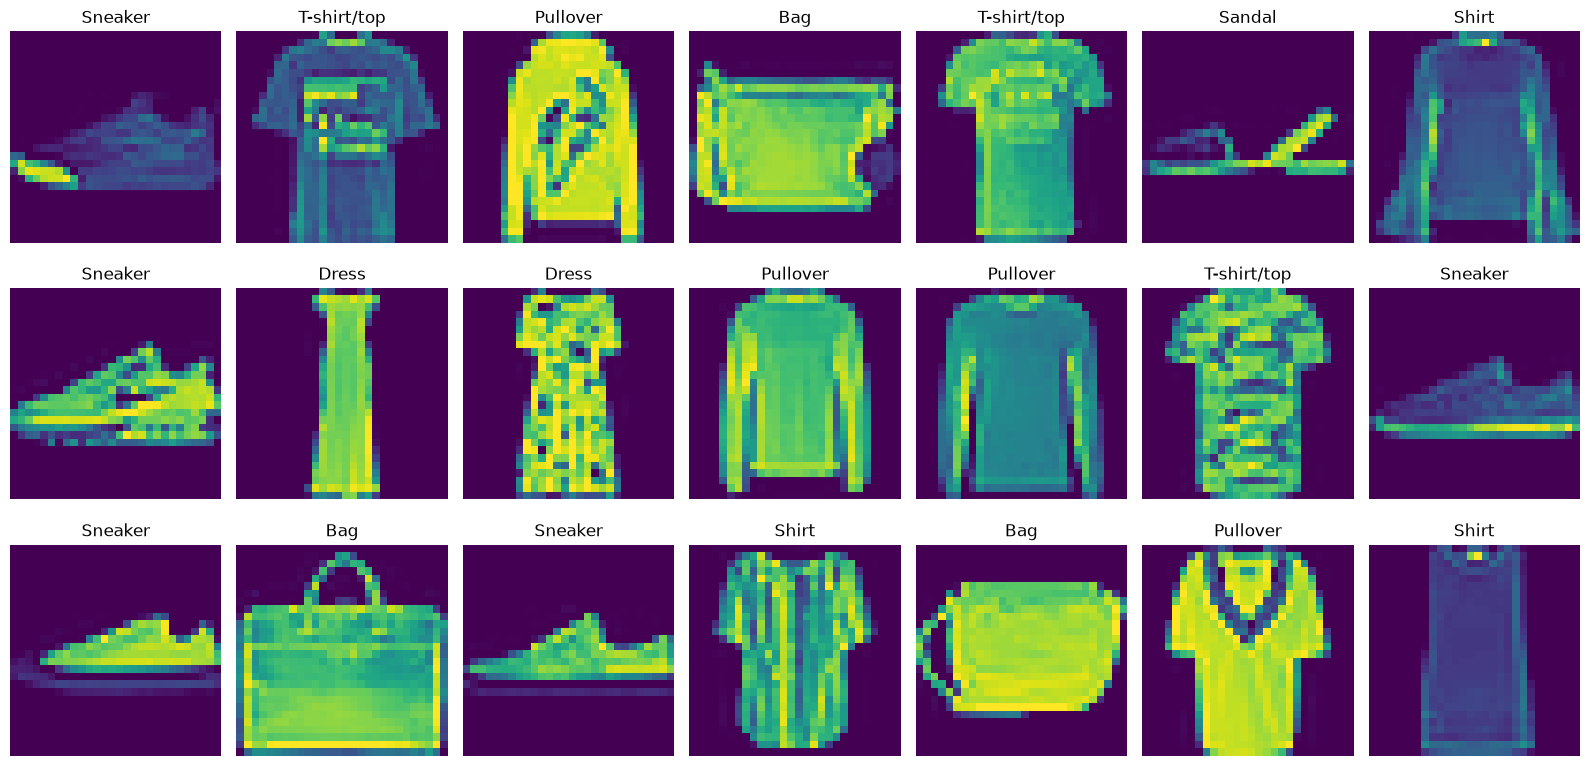

In [48]:
# Plot the first few figures in X_test along with its labels from y_test

plt.figure(figsize=(16, 8))

for i in range(21):
    plt.subplot(3, 7, i + 1)
    plt.imshow(X_test[i])
    plt.title(labels[y_test.iloc[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

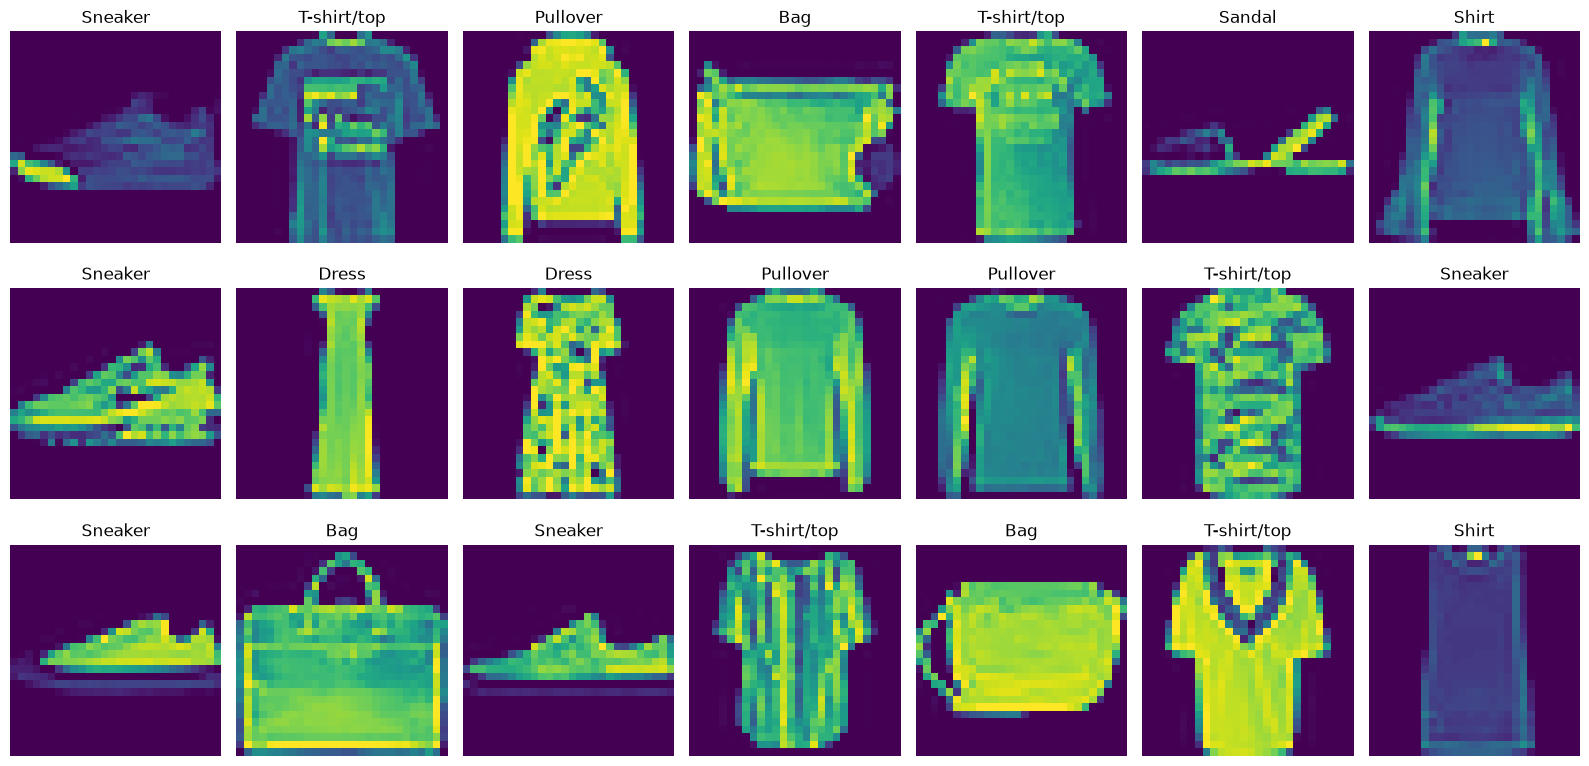

In [50]:
# Now plot the figures from X-test with labels from our Predicted values

plt.figure(figsize=(16, 8))

for i in range(21):
    plt.subplot(3, 7, i + 1)
    plt.imshow(X_test[i])
    plt.title(labels[predicted_values[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

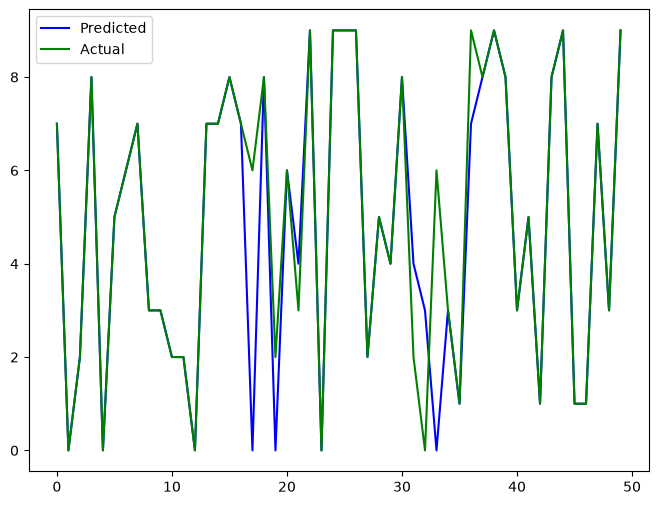

In [51]:
c = range(len(predicted_values))
plt.figure(figsize = (8,6))
plt.plot(c[:50], predicted_values[:50], color = 'blue')
plt.plot(c[:50], y_test[:50], color = 'green')
plt.legend(['Predicted', 'Actual'])
plt.show()

Text(70.83333333333333, 0.5, 'Actual Values')

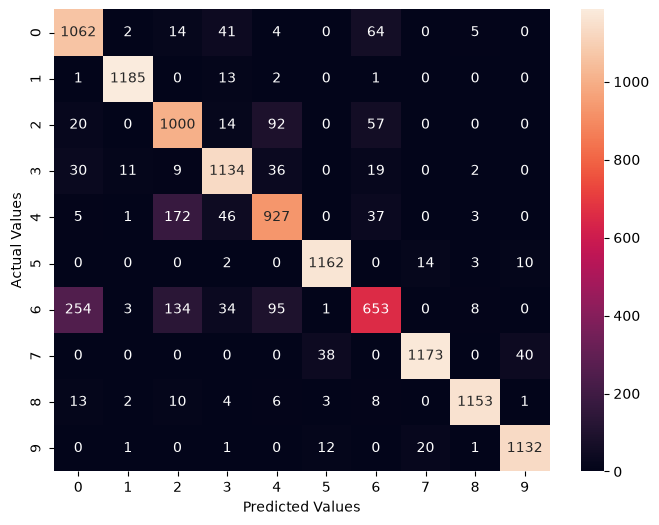

In [52]:
plt.figure(figsize = (8,6))
sns.heatmap(confusion_matrix(y_test,predicted_values), annot = True, fmt = 'd')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

# CONVOLUTIONAL NEURAL NETWORK (CNN)

## Project - Brain Tumor Classification (MRI)

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.utils import shuffle
from skimage.transform import resize
from sklearn.metrics import confusion_matrix
import glob

In [52]:
# Fetch the training Data

glioma_tumor=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Training/glioma_tumor/*.jpg")
meningioma_tumor=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Training/meningioma_tumor/*.jpg")
no_tumor=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Training/no_tumor/*.jpg")
pituitary_tumor=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Training/pituitary_tumor/*.jpg")

In [53]:
# Fetch the testing data

glioma_tumor_test=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Testing/glioma_tumor/*.jpg")
meningioma_tumor_test=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Testing/meningioma_tumor/*.jpg")
no_tumor_test=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Testing/no_tumor/*.jpg")
pituitary_tumor_test=glob.glob("Downloads/Brain Tumour Classification Files/Brain Tumour Classification Files/Brain_tumor/Testing/pituitary_tumor/*.jpg")

In [54]:
# Find the number of images of all classes in the Training set

print("Number of images in Training set are:")
print("Glioma:", len(glioma_tumor))
print("Meningioma:", len(meningioma_tumor))
print("No Tumor:", len(no_tumor))
print("Pituitary:", len(pituitary_tumor))

Number of images in Training set are:
Glioma: 84
Meningioma: 72
No Tumor: 72
Pituitary: 84


In [55]:
# Find the number of images of all classes in the testing set

print("Number of images in Testing set are:")
print("Glioma:", len(glioma_tumor_test))
print("Meningioma:", len(meningioma_tumor_test))
print("No Tumor:", len(no_tumor_test))
print("Pituitary:", len(pituitary_tumor_test))

Number of images in Testing set are:
Glioma: 24
Meningioma: 24
No Tumor: 24
Pituitary: 24


In [56]:
# Store all the images inside a list and create a list with the corresponding labels
# For Training set

image = []
label = []

for i in glioma_tumor:
    img = plt.imread(i)
    image.append(img)
    label.append(0)

    
for i in meningioma_tumor:
    img = plt.imread(i)
    image.append(img)
    label.append(1)

for i in no_tumor:
    img = plt.imread(i)
    image.append(img)
    label.append(2)

for i in pituitary_tumor:
    img = plt.imread(i)
    image.append(img)
    label.append(3)

In [80]:
# For Testing set

image_test = []
label_test = []

for i in glioma_tumor_test:
    img = plt.imread(i)
    image_test.append(img)
    label_test.append(0)

    
for i in meningioma_tumor_test:
    img = plt.imread(i)
    image_test.append(img)
    label_test.append(1)

for i in no_tumor_test:
    img = plt.imread(i)
    image_test.append(img)
    label_test.append(2)

for i in pituitary_tumor_test:
    img = plt.imread(i)
    image_test.append(img)
    label_test.append(3)

In [81]:
# Shuffle both images and labels
# Training set

image, label = shuffle(image,label, random_state = 100)

In [82]:
# Testing set

image_test, label_test = shuffle(image_test,label_test, random_state = 100)

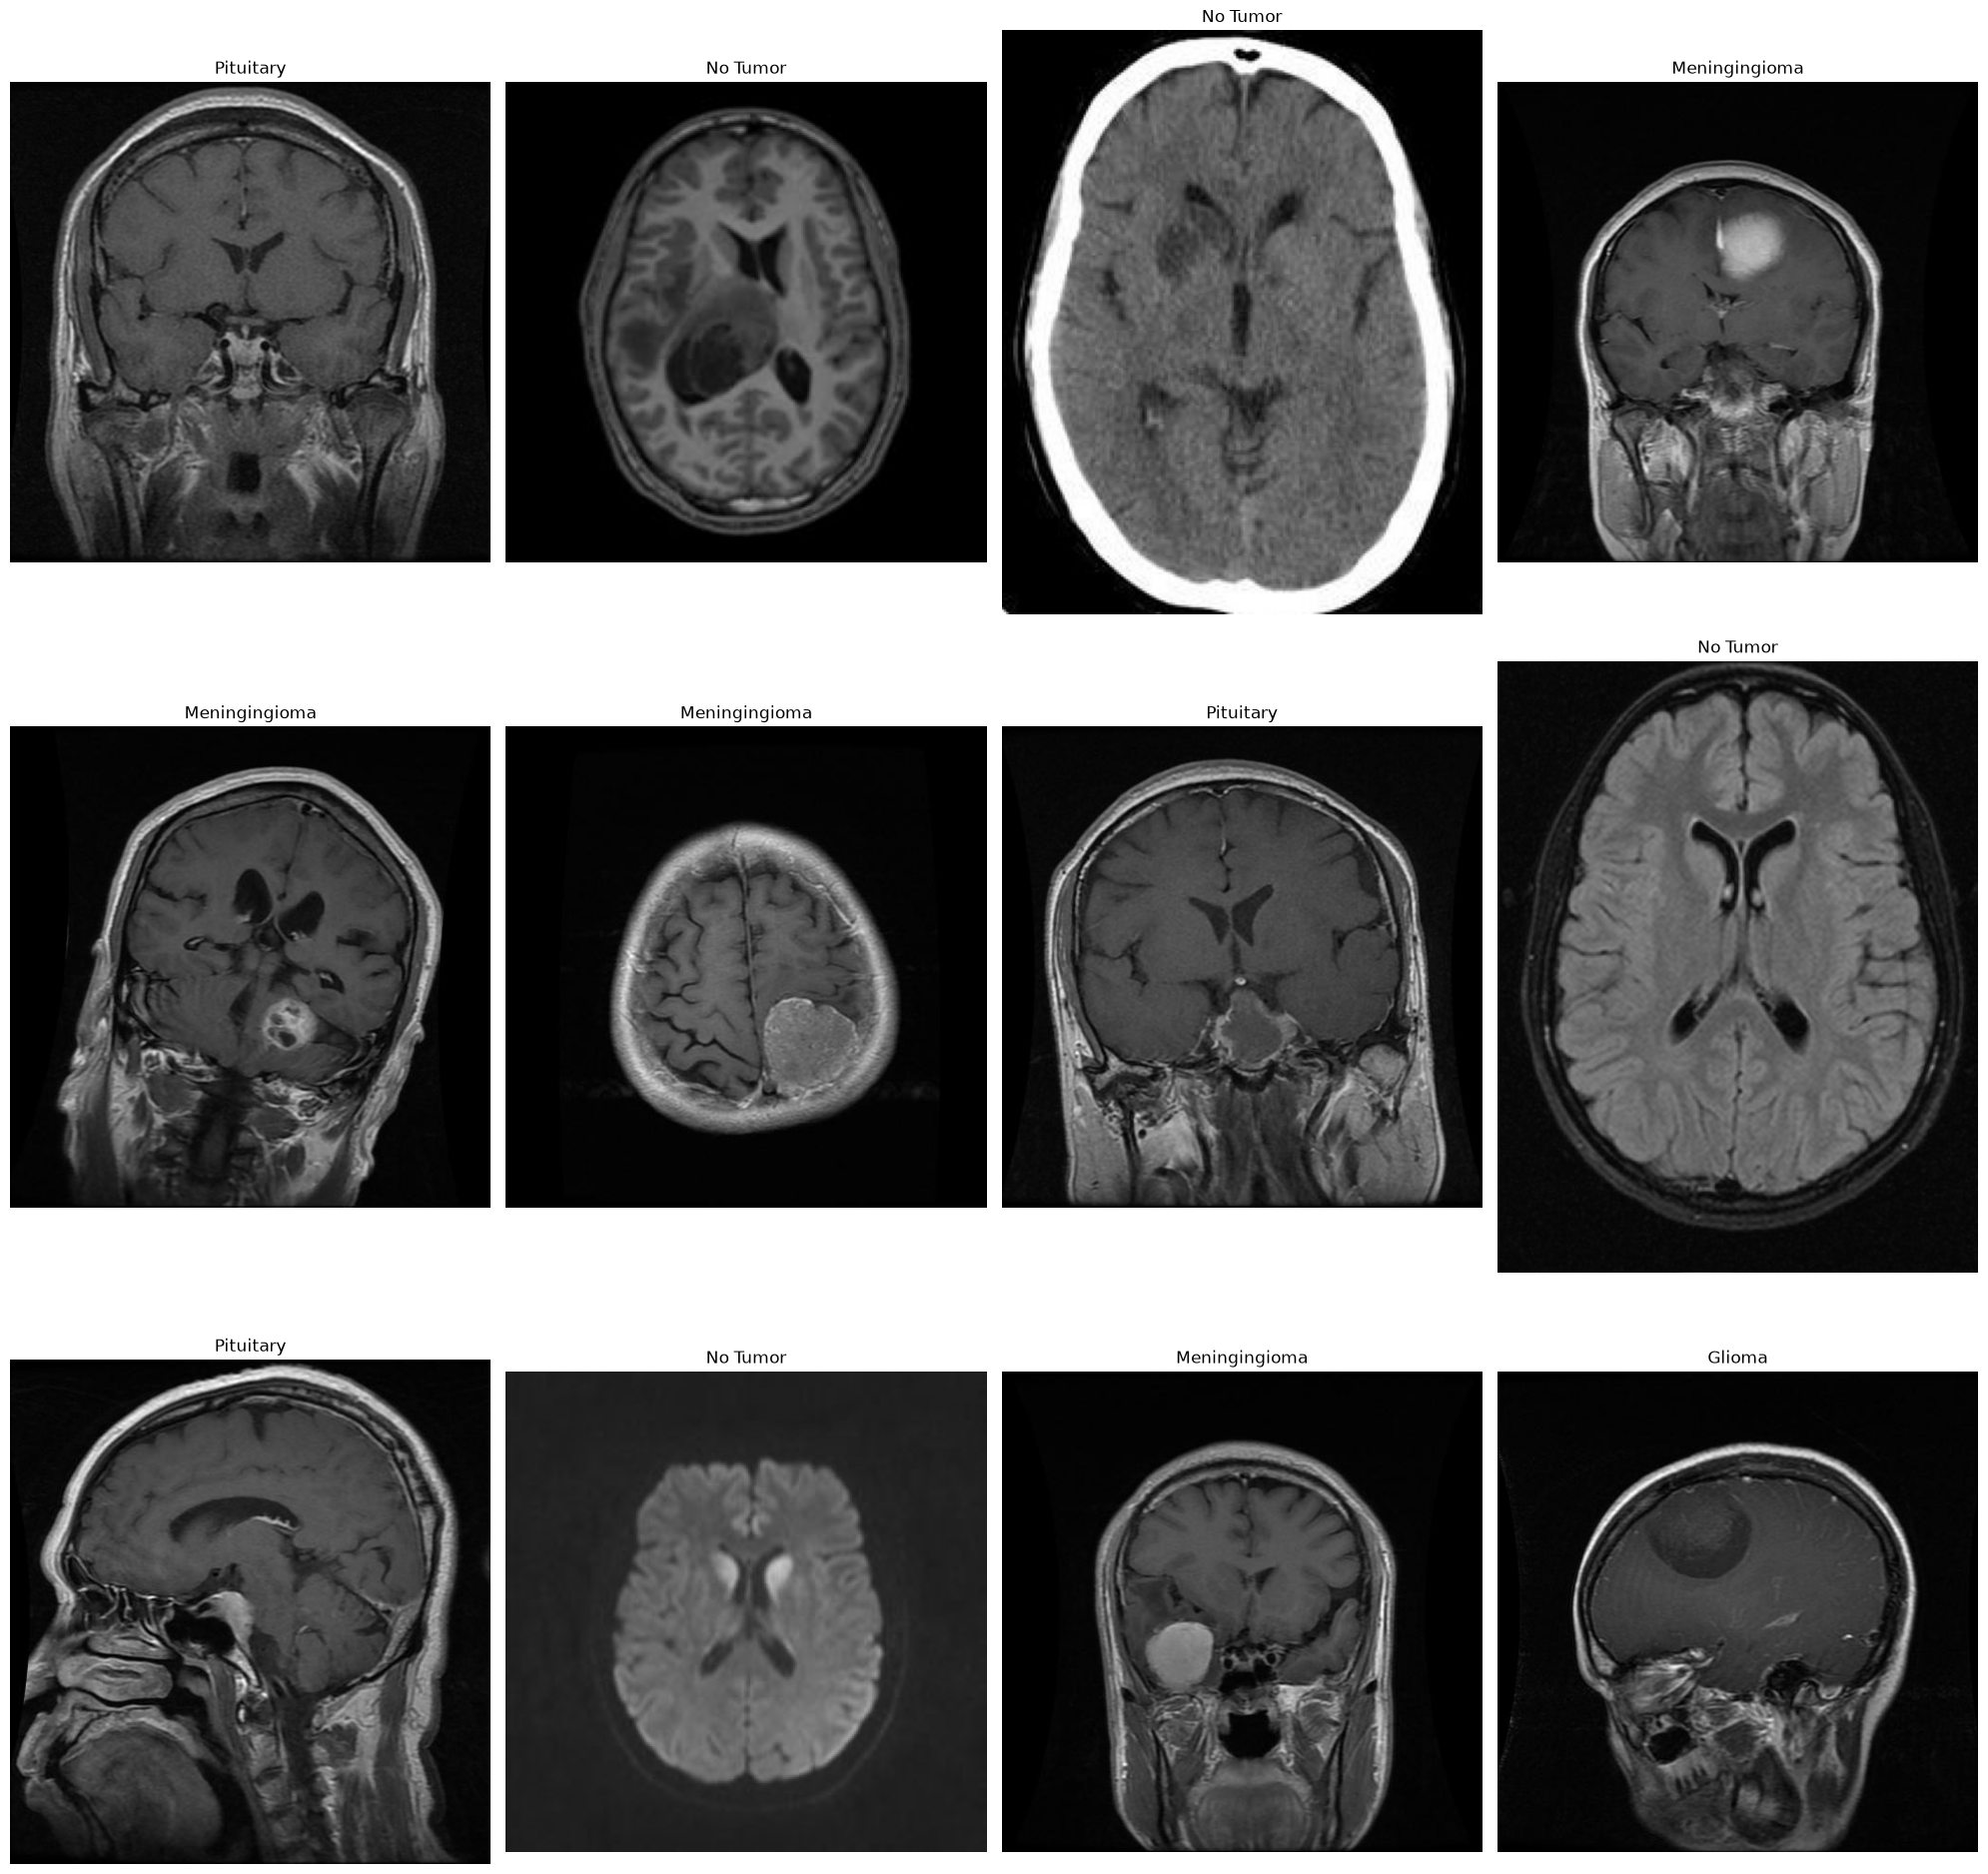

In [83]:
# Plot a few images from our shuffled list with its corresponding label

plt.figure(figsize=(20,20))

for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(image[i])

    if label[i] == 0:
        plt.title("Glioma")
    elif label[i] == 1:
        plt.title("Meningingioma")
    elif label[i] == 2:
        plt.title("No Tumor")
    else:
        plt.title("Pituitary")

    plt.axis('off')

plt.tight_layout()
plt.show()

In [84]:
# Check the shape of the first 10 images in our list (Either from training or test set)

for i in range(10):
    print(f"Image {i} shape:",image[i].shape)

Image 0 shape: (512, 512, 3)
Image 1 shape: (236, 236, 3)
Image 2 shape: (249, 205, 3)
Image 3 shape: (512, 512, 3)
Image 4 shape: (512, 512, 3)
Image 5 shape: (512, 512, 3)
Image 6 shape: (512, 512, 3)
Image 7 shape: (452, 355, 3)
Image 8 shape: (512, 488, 3)
Image 9 shape: (236, 236, 3)


In [85]:
# # Resize the images to 224X224
# Training set

X_train = []

for i in image:
    X_train.append(resize(i,(224,224,3)))
    
X_train = np.array(X_train)

In [86]:
# Testing set

X_test = []

for i in image_test:
    X_test.append(resize(i,(224,224,3)))
    
X_test = np.array(X_test)

In [87]:
# Check the datatype of X_train and Label

print(type(X_train))
print(type(label))

<class 'numpy.ndarray'>
<class 'list'>


In [88]:
# Convert label and test_label to Numpy array and store it in y_train and y_test

y_train = np.array(label)
y_test = np.array(label_test)

In [89]:
print(type(y_train))
print(type(y_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


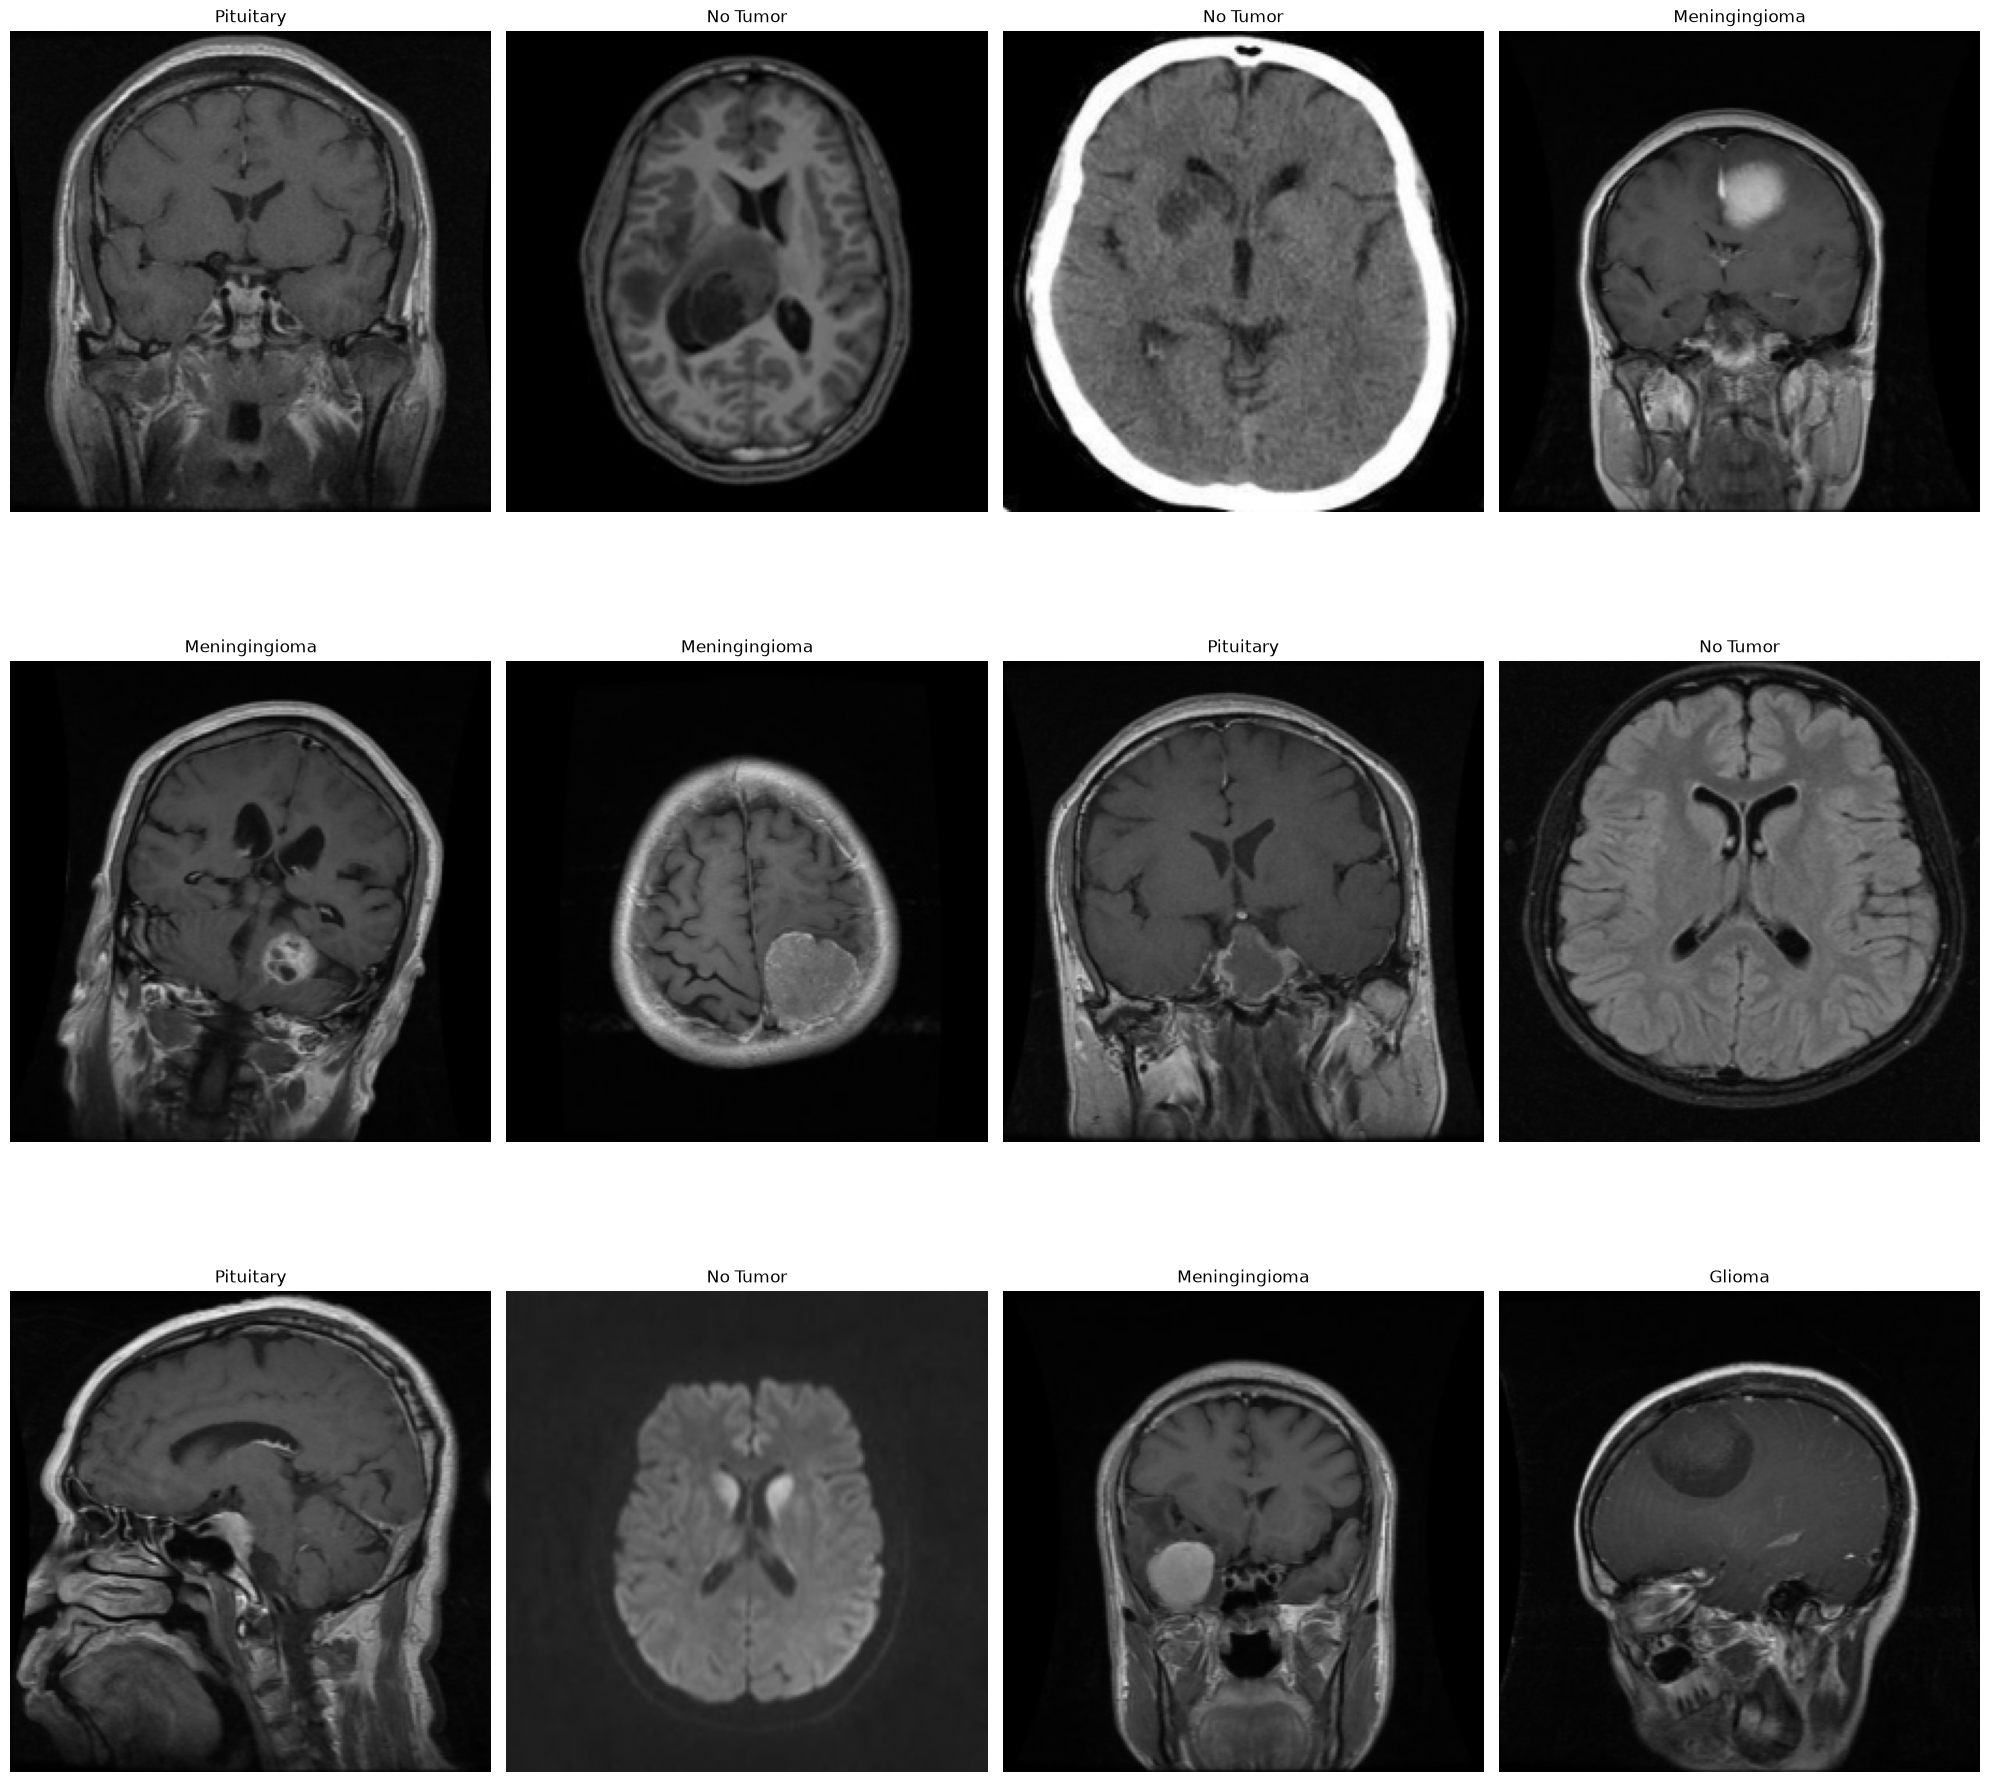

In [90]:
# Plot some of our reshaped images

plt.figure(figsize=(20,20))

for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(X_train[i])

    if label[i] == 0:
        plt.title("Glioma")
    elif label[i] == 1:
        plt.title("Meningingioma")
    elif label[i] == 2:
        plt.title("No Tumor")
    else:
        plt.title("Pituitary")

    plt.axis('off')

plt.tight_layout()
plt.show()

In [91]:
# Check the shape of X_train and X_test and y_train and y_test

print("Shape of X_train is:", X_train.shape)
print("Shape of X_test is:", X_test.shape)
print("Shape of y_train is:", y_train.shape)
print("Shape of y_test is:", y_test.shape)

Shape of X_train is: (408, 224, 224, 3)
Shape of X_test is: (96, 224, 224, 3)
Shape of y_train is: (408,)
Shape of y_test is: (96,)


In [92]:
# Create a keras Sequential model with convolution layers, Flatten and  Hidden layers

model = keras.models.Sequential([
    keras.layers.Conv2D(16, (3,3), activation = 'relu', input_shape = (224, 224, 3)),
    keras.layers.MaxPool2D(2,2),
    
    keras.layers.Conv2D(32,(3,3), activation = 'relu'),
    keras.layers.MaxPool2D(2,2),

    keras.layers.Conv2D(32,(3,3), activation = 'relu'),
    keras.layers.MaxPool2D(2,2),
    
    keras.layers.Flatten(),
    
    keras.layers.Dense(64, activation = 'relu'),
    keras.layers.Dense(4, activation = 'softmax')
])

In [93]:
# Compile the model

model.compile(optimizer = 'adam',
             loss = 'sparse_categorical_crossentropy',
             metrics = ['accuracy'])

In [94]:
# Check the summary of our model

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                    │ (None, 222, 222, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 111, 111, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 109, 109, 32)        │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 54, 54, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 52, 52, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 26, 26, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 21632)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │       1,384,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,399,108 (5.34 MB)

 Trainable params: 1,399,108 (5.34 MB)

 Non-trainable params: 0 (0.00 B)

In [95]:
# Train the model

model.fit(X_train,y_train, epochs=30, steps_per_epoch=20, validation_split=0.1)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 286ms/step - accuracy: 0.4496 - loss: 1.2386 - val_accuracy: 0.8049 - val_loss: 0.8056
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 243ms/step - accuracy: 0.7575 - loss: 0.6926 - val_accuracy: 0.8293 - val_loss: 0.6412
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - accuracy: 0.8365 - loss: 0.4986 - val_accuracy: 0.8537 - val_loss: 0.5326
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 243ms/step - accuracy: 0.9292 - loss: 0.2389 - val_accuracy: 0.8537 - val_loss: 0.6743
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 241ms/step - accuracy: 0.9564 - loss: 0.1170 - val_accuracy: 0.9268 - val_loss: 0.6036
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 245ms/step - accuracy: 0.9918 - loss: 0.0636 - val_accuracy: 0.8780 - val_loss: 0.5958
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 256ms/step - accuracy: 0.9973 - loss: 0.0155 - val_accuracy: 0.9024 - val_loss: 0.9345
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 246ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 0.

In [96]:
# Evaluate the model

model.evaluate(X_train, y_train)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 126ms/step - accuracy: 0.9902 - loss: 0.1059


[0.10587470978498459, 0.9901960492134094]

In [97]:
# Make predictions with X_test

prediction = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 137ms/step


In [98]:
prediction[:5]

array([[1.51834755e-07, 2.81206858e-09, 1.03476020e-06, 9.99998808e-01],
       [1.04375594e-07, 2.76976825e-05, 2.96329654e-06, 9.99969244e-01],
       [1.53251767e-05, 9.99887705e-01, 8.64866015e-05, 1.05189874e-05],
       [4.24004915e-10, 9.99999881e-01, 7.35654098e-08, 1.62533806e-11],
       [2.39084141e-10, 9.99942541e-01, 5.74964979e-05, 2.56484195e-10]],
      dtype=float32)

In [99]:
# Use np.argmax to fetch indices of max element of the array
# Store the values in a list

predicted_labels = np.argmax(prediction, axis=1).tolist()

In [102]:
print(predicted_labels)

[3, 3, 1, 1, 1, 3, 1, 1, 2, 2, 0, 1, 1, 2, 1, 3, 1, 3, 3, 3, 0, 0, 0, 0, 1, 0, 1, 1, 1, 2, 0, 2, 1, 3, 2, 2, 2, 3, 3, 0, 3, 3, 0, 0, 1, 1, 1, 3, 3, 2, 2, 1, 3, 3, 0, 1, 1, 2, 3, 3, 2, 2, 2, 3, 2, 2, 1, 2, 0, 3, 2, 3, 0, 0, 1, 0, 1, 0, 0, 2, 2, 2, 0, 3, 1, 0, 2, 2, 2, 0, 2, 3, 3, 2, 1, 0]


In [104]:
predicted_labels[:5]

[3, 3, 1, 1, 1]

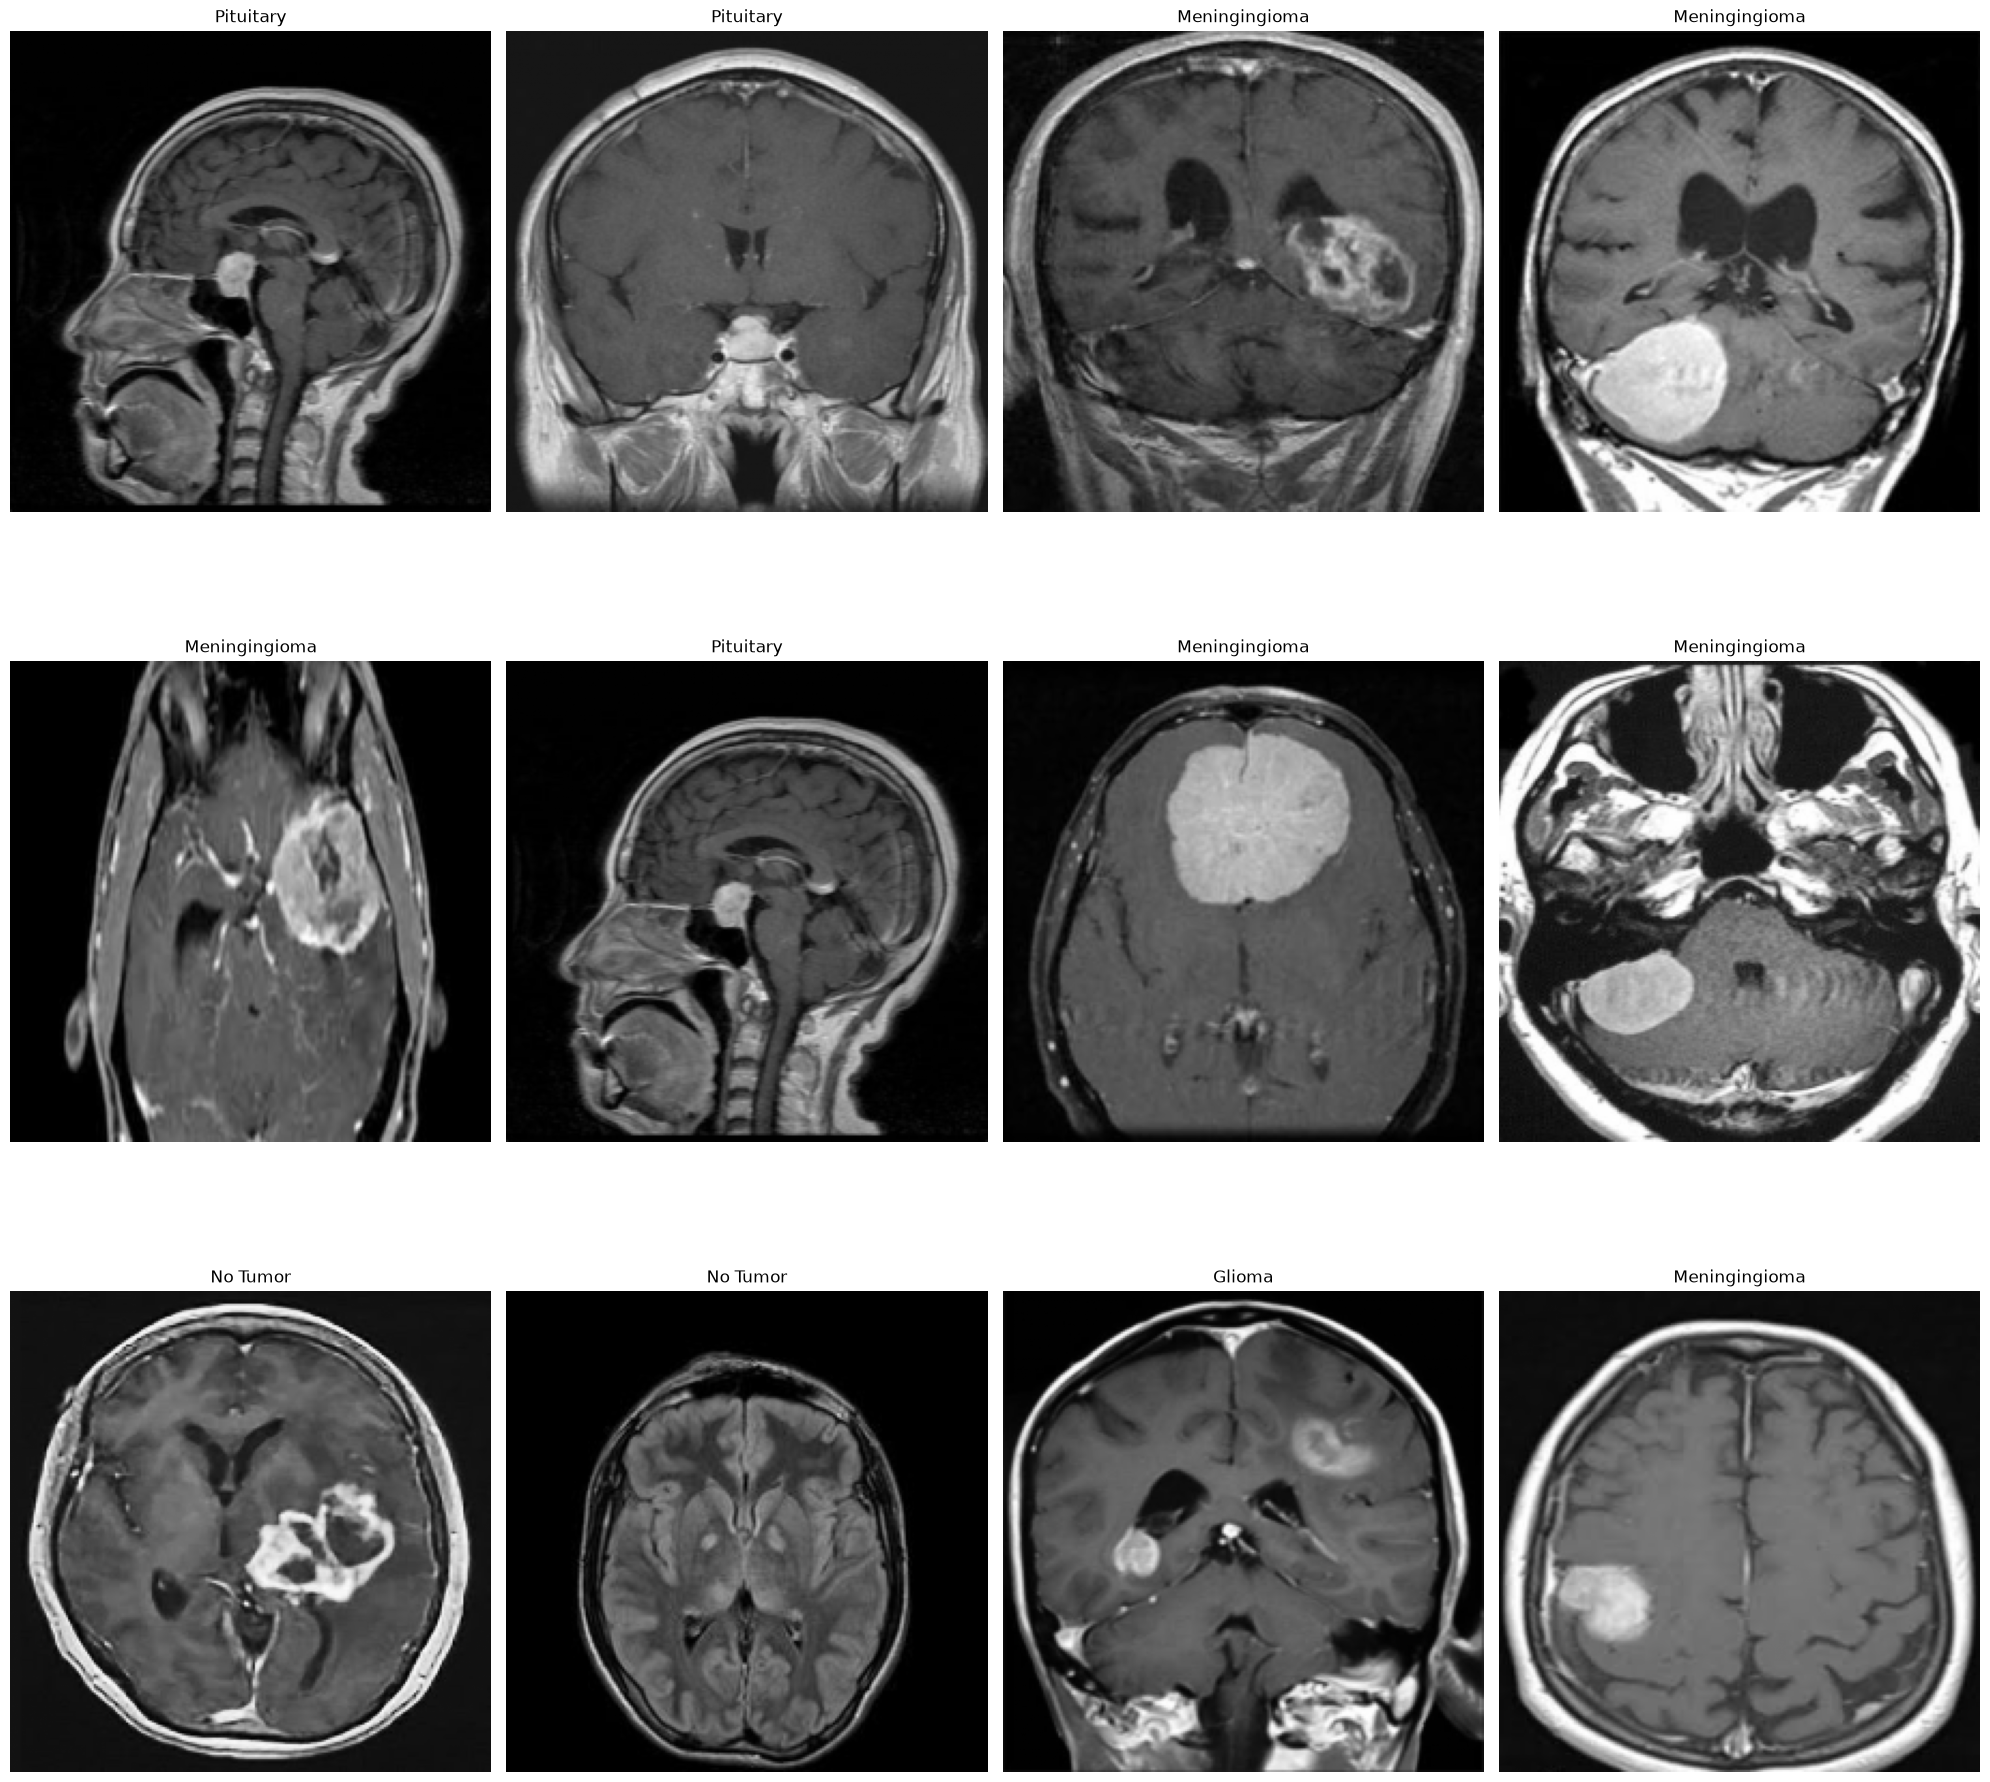

In [106]:
# Plot X_test with label from our prediction

plt.figure(figsize=(20,20))

for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(X_test[i])

    if predicted_labels[i] == 0:
        plt.title("Glioma")
    elif predicted_labels[i] == 1:
        plt.title("Meningingioma")
    elif predicted_labels[i] == 2:
        plt.title("No Tumor")
    else:
        plt.title("Pituitary")

    plt.axis('off')

plt.tight_layout()
plt.show()

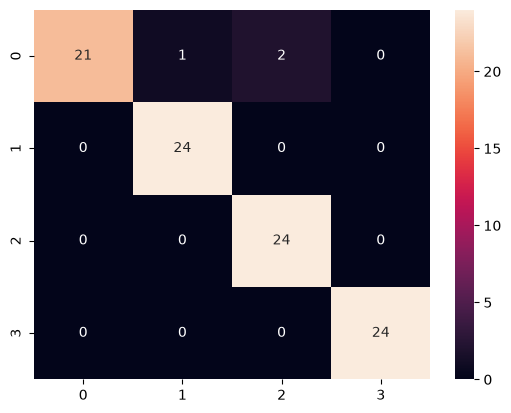

In [108]:
# Visualise confusion matrix on a heatmap

sns.heatmap(confusion_matrix(y_test,predicted_labels), annot = True)
plt.show()

# RECURRENT NEURAL NETWORK (RNN)

## Project - IMBD Movie review Classification Project

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('Downloads/IMBD Movie Review - Sentiment Analysis Files/IMDB Dataset.csv')
df=df.iloc[:10000]

In [4]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     10000 non-null  object
 1   sentiment  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB


In [6]:
df.describe()

,review,sentiment
count,10000,10000
unique,9983,2
top,"Beautiful film, pure Cassavetes style. Gena Ro...",positive
freq,2,5028


C:\Users\varsh\AppData\Local\Temp\ipykernel_19440\2257561628.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='sentiment', data=df, order=counts.index,palette=['#1f77b4', '#ff7f0e'])


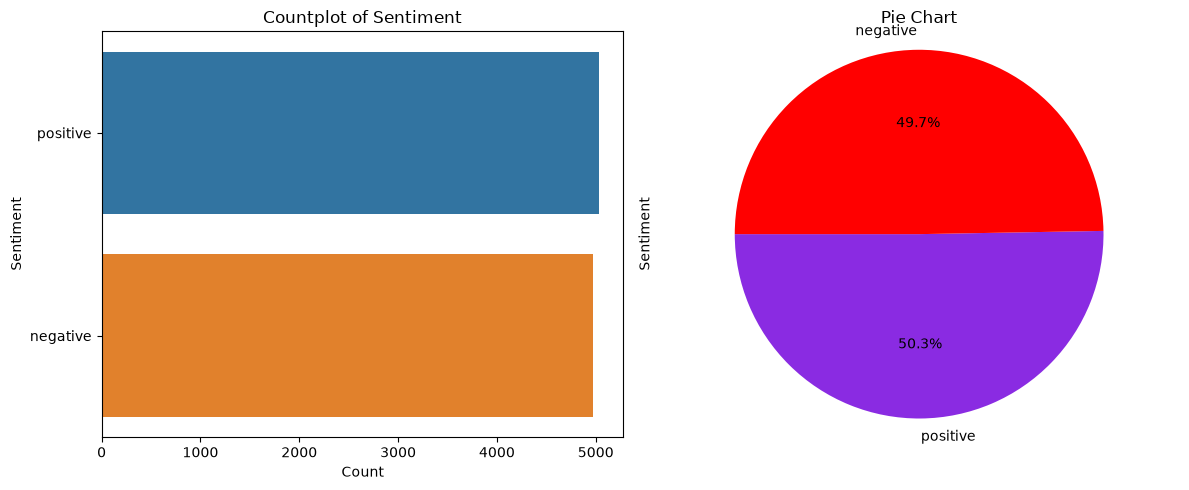

In [7]:
# Check for imbalanced data

# Count the occurrences of each class
counts = df['sentiment'].value_counts()

# Create figure
plt.figure(figsize=(12,5))

# Countplot
plt.subplot(1,2,1)
sns.countplot(y='sentiment', data=df, order=counts.index,palette=['#1f77b4', '#ff7f0e'])
plt.title('Countplot of Sentiment')
plt.xlabel('Count')
plt.ylabel('Sentiment')

# Pie Chart
plt.subplot(1,2,2)
plt.pie(counts,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=180,
        colors=['#8A2BE2', '#FF0000'])
plt.title('Pie Chart')
plt.axis('equal')
plt.ylabel('Sentiment')

plt.tight_layout()
plt.show()

In [8]:
# Create a function to Preprocess the review column

import re # regular expression
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer 

In [9]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\varsh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [10]:
stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [11]:
def preprocess(sentence):
    #removes all the special characters and split the sentence at spaces
    text = re.sub(r"[^a-zA-Z0-9]"," ",sentence).split()
    
    # converts words to lowercase and removes any stopwords 
    words = [x.lower() for x in text if x not in stopwords.words('english')]
    
    # Lemmatize the words
    lemma = WordNetLemmatizer() 
    word = [lemma.lemmatize(word,'v') for word in words ]
    
    # convert the list of words back into a sentence
    word = ' '.join(word)
    return word

In [12]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\varsh\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [13]:
# Create a function to Preprocess the review column

df['review'] = df['review'].apply(preprocess)

In [14]:
# Print some text after applying the function

for i in range(10):
    print(df['review'][i])
    print()

one reviewers mention watch 1 oz episode hook they right exactly happen br br the first thing strike oz brutality unflinching scenes violence set right word go trust show faint hearted timid this show pull punch regard drug sex violence its hardcore classic use word br br it call oz nickname give oswald maximum security state penitentary it focus mainly emerald city experimental section prison cells glass front face inwards privacy high agenda em city home many aryans muslims gangstas latinos christians italians irish scuffle death star dodgy dealings shady agreements never far away br br i would say main appeal show due fact go show dare forget pretty picture paint mainstream audiences forget charm forget romance oz mess around the first episode i ever saw strike nasty surreal i say i ready i watch i develop taste oz get accustom high level graphic violence not violence injustice crook guard sell nickel inmates kill order get away well mannered middle class inmates turn prison bitch d

In [15]:
# Split the dataset into Input (X) & Target (y) variable

X = df['review']
y = df['sentiment']

In [16]:
# Convert y variable values into 0 and 1 from positive and negative

y=y.map({'positive':1,'negative':0})

In [17]:
y

0       1
1       1
2       1
3       0
4       1
       ..
9995    1
9996    0
9997    0
9998    0
9999    1
Name: sentiment, Length: 10000, dtype: int64

In [18]:
# Split the dataset into Training and Testing Set

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.20)

In [19]:
# ### Create Keras tokenizer object with 5000 max words
# Convert text to sequence
# Add padding

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [20]:
tokenizer = Tokenizer(num_words=5000)

In [21]:
tokenizer.fit_on_texts(X_train)

In [22]:
vocab_size = len(tokenizer.word_index) + 1

In [23]:
tokenizer

In [24]:
def text_encoding(txt):
    # texts_to_sequences Transforms each text in texts to a sequence of integers.
    encoded_docs = tokenizer.texts_to_sequences(txt)
    
    # pad_sequences is used to ensure that all sequences in a list have the same length.
    padded_sequence = pad_sequences(encoded_docs, maxlen=128)    
       
    return padded_sequence

In [25]:
X_train = text_encoding(X_train)
X_test = text_encoding(X_test)

In [26]:
# Create keras Sequential Model with LSTM Layers

vocab_size

39906

In [27]:
from keras import Sequential
from keras import layers

In [40]:
model = Sequential()
### Embedding layer
# vocab size= Number of unique words in our training set
# Second argument (In this case "200" is the size of each embedding layer
model.add(layers.Input(shape=(200,)))
model.add(layers.Embedding(input_dim=vocab_size,output_dim= 128))

### Lstm layer
### return_sequences: Whether to return the last output in the output sequence, or the full sequence.
model.add(layers.LSTM(128,  return_sequences=True))
model.add(layers.Dropout(0.2))
model.add(layers.LSTM(128))
model.add(layers.Dense(64, activation = 'relu'))
model.add(layers.Dropout(0.2))

model.add(layers.Dense(1, activation='sigmoid'))

In [41]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ (None, 200, 128)            │       5,107,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_6 (LSTM)                        │ (None, 200, 128)            │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 200, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_7 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,379,457 (20.52 MB)

 Trainable params: 5,379,457 (20.52 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# Compile the model

model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [43]:
# Train the model with our training set

model.fit(X_train, y_train, epochs=10, validation_split = 0.2)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 37s 171ms/step - accuracy: 0.7644 - loss: 0.4759 - val_accuracy: 0.8512 - val_loss: 0.3653
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 44s 185ms/step - accuracy: 0.9038 - loss: 0.2464 - val_accuracy: 0.8438 - val_loss: 0.3857
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 39s 196ms/step - accuracy: 0.9405 - loss: 0.1586 - val_accuracy: 0.8506 - val_loss: 0.4958
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 46s 231ms/step - accuracy: 0.9675 - loss: 0.0912 - val_accuracy: 0.8438 - val_loss: 0.5344
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 43s 213ms/step - accuracy: 0.9833 - loss: 0.0468 - val_accuracy: 0.8231 - val_loss: 0.7073
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 74s 172ms/step - accuracy: 0.9867 - loss: 0.0380 - val_accuracy: 0.7994 - val_loss: 0.7003
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 41s 171ms/step - accuracy: 0.9903 - loss: 0.0292 - val_accuracy: 0.8306 - val_loss: 0.9854
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 41s 173ms/step - accuracy: 0.9884 - loss: 0

In [46]:
# Make prediction with X_test

y_pred_prob = model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step


In [47]:
y_pred_prob

array([[6.5475452e-01],
       [9.9991143e-01],
       [1.3153296e-03],
       ...,
       [1.8210875e-04],
       [9.8863691e-02],
       [9.9983752e-01]], shape=(2000, 1), dtype=float32)

In [48]:
#  Convert to 0 and 1 with higher probability towards 1

y_pred=(y_pred_prob>0.5).astype(int).flatten()

In [49]:
y_pred

array([1, 1, 0, ..., 0, 0, 1], shape=(2000,))

In [50]:
#  Evaluate the model

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [51]:
# Check accuracy score

accuracy_score(y_test, y_pred)

0.825

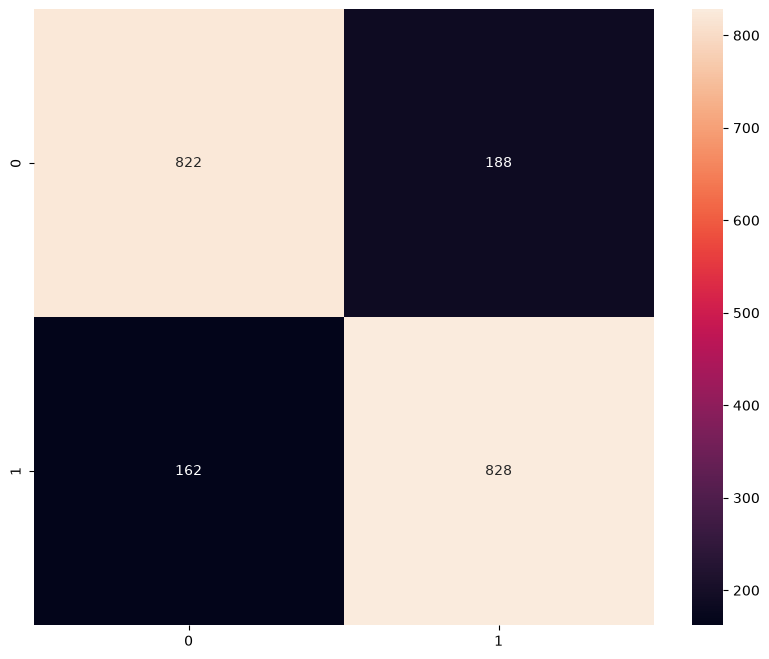

In [52]:
# Check confusion matrix

plt.figure(figsize = (10,8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = 'd')
plt.show()

In [54]:
# Print Classification report

print(classification_report(y_test, y_pred,target_names=['Negative','Positive']))

              precision    recall  f1-score   support

    Negative       0.84      0.81      0.82      1010
    Positive       0.81      0.84      0.83       990

    accuracy                           0.82      2000
   macro avg       0.83      0.83      0.82      2000
weighted avg       0.83      0.82      0.82      2000



# GATED RECURRENT NETWORK (GRU)

## Project - Spooky Author Identification

In [55]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.preprocessing import LabelBinarizer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [56]:
# Read 'spooky.csv' dataset

df = pd.read_csv('Downloads/Spooky Author Identification Files/spooky.csv')

In [57]:
# Save only a portion of the dataset

df = df[0:20000]

In [58]:
df.head()

,id,text,author
0,id26305,"This process, however, afforded me no means of...",EAP
1,id17569,It never once occurred to me that the fumbling...,HPL
2,id11008,"In his left hand was a gold snuff box, from wh...",EAP
3,id27763,How lovely is spring As we looked from Windsor...,MWS
4,id12958,"Finding nothing else, not even gold, the Super...",HPL


In [59]:
# Shuffle the dataset

df = df.sample(frac = 1)

In [60]:
df.reset_index(drop = True, inplace = True)

In [61]:
# Drop 'id' column

df.drop(columns=['id'], inplace=True)

In [62]:
df

,text,author
0,It is long since I first trod the deck of this...,EAP
1,"Arithmetical or algebraical calculations are, ...",EAP
2,It has a certain general relation to the vario...,EAP
3,"Meantime the devil, to whom the copy was entru...",EAP
4,Yet it is not wonderful that these conceptions...,EAP
...,...,...
19574,They are undoubtedly part of PEAAEMA.,EAP
19575,Neither yours nor any man's death is needed to...,MWS
19576,The guest is bidden to be of good cheer that t...,EAP
19577,We had entered the Castle.,MWS


In [63]:
# Check Info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19579 entries, 0 to 19578
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    19579 non-null  object
 1   author  19579 non-null  object
dtypes: object(2)
memory usage: 306.1+ KB


In [64]:
# View basic statistical information about the dataset

df.describe()

,text,author
count,19579,19579
unique,19579,3
top,It is long since I first trod the deck of this...,EAP
freq,1,7900


In [65]:
# Check for missing values

df.isna().sum()

text      0
author    0
dtype: int64

In [66]:
# Check for duplicates

print(df.duplicated().sum())

0


In [67]:
# Print some of the text along with its author

for i in range(10):
    print(df['text'][i],'-', df['author'][i])
    print()

It is long since I first trod the deck of this terrible ship, and the rays of my destiny are, I think, gathering to a focus. - EAP

Arithmetical or algebraical calculations are, from their very nature, fixed and determinate. - EAP

It has a certain general relation to the various styles of building. - EAP

Meantime the devil, to whom the copy was entrusted, ran up stairs to his 'case,' in an unutterable hurry, and forthwith made a commencement at 'setting' the MS. - EAP

Yet it is not wonderful that these conceptions are indefinite, since they have their origin in sources so utterly novel. - EAP

The balloon at first collapsed, then furiously expanded, then whirled round and round with horrible velocity, and finally, reeling and staggering like a drunken man, hurled me with great force over the rim of the car, and left me dangling, at a terrific height, with my head downward, and my face outwards, by a piece of slender cord about three feet in length, which hung accidentally through a 

In [68]:
# Create a function to preproces the text

def preprocess(sentence):
    #removes all the special characters and split the sentence at spaces
    text = re.sub(r"[^a-zA-Z0-9]"," ",sentence).split()
    
    # converts words to lowercase and removes any stopwords
    words = [x.lower() for x in text if x not in stopwords.words('english')]
    
    # Lemmatize the words
    lemma = WordNetLemmatizer()
    word = [lemma.lemmatize(word,'v') for word in words ]
    
    # convert the list of words back into a sentence
    word = ' '.join(word)
    return word

In [69]:
df['text'] = df['text'].apply(preprocess)

In [70]:
# Print some of the text after preprocess

for i in range(10):
    print(df['text'][i],'-', df['text'][i])
    print()

it long since i first tread deck terrible ship ray destiny i think gather focus - it long since i first tread deck terrible ship ray destiny i think gather focus

arithmetical algebraical calculations nature fix determinate - arithmetical algebraical calculations nature fix determinate

it certain general relation various style build - it certain general relation various style build

meantime devil copy entrust run stairs case unutterable hurry forthwith make commencement set ms - meantime devil copy entrust run stairs case unutterable hurry forthwith make commencement set ms

yet wonderful conceptions indefinite since origin source utterly novel - yet wonderful conceptions indefinite since origin source utterly novel

the balloon first collapse furiously expand whirl round round horrible velocity finally reel stagger like drunken man hurl great force rim car leave dangle terrific height head downward face outwards piece slender cord three feet length hang accidentally crevice near bot

C:\Users\varsh\AppData\Local\Temp\ipykernel_19440\206474354.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='author', data=df, palette='Set2')


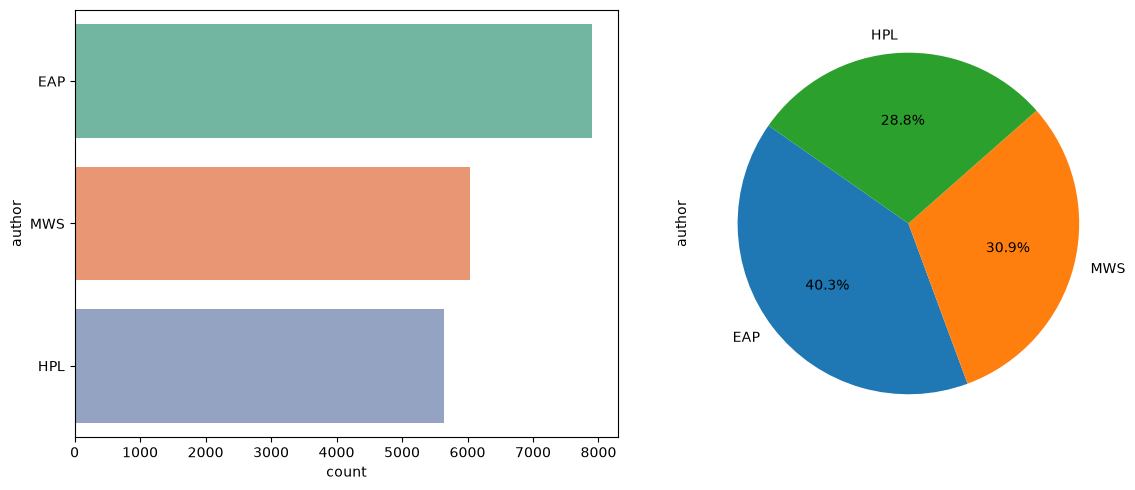

In [71]:
# Check for imbalance in the dataset
# Count the occurrences of each class

plt.figure(figsize=(12,5))

# Horizontal Count Plot
plt.subplot(1,2,1)
sns.countplot(y='author', data=df, palette='Set2')
plt.xlabel('count')
plt.ylabel('author')

# Pie Chart
plt.subplot(1,2,2)
author_count = df['author'].value_counts()

plt.pie(
    author_count,
    labels=author_count.index,
    autopct='%1.1f%%',
    startangle=145
)

plt.ylabel('author')

plt.tight_layout()
plt.show()

In [74]:
# Split the dataset into Input & Target Variables

X = df['text']
y = df['author']

In [75]:
# Label Encode our target variables

from sklearn.preprocessing import LabelBinarizer

In [76]:
encoder = LabelBinarizer()
y = encoder.fit_transform(y)

In [77]:
labels = encoder.classes_
labels

array(['EAP', 'HPL', 'MWS'], dtype='<U3')

In [78]:
# Split the dataset into Training & Testing Set

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.20)

In [79]:
# Create Keras tokenizer object with 5000 max words
# Convert text to sequence
# Add padding

tokenizer = Tokenizer(num_words=5000)

In [80]:
# fit on text for our X

tokenizer.fit_on_texts(X)

In [81]:
vocab_size = len(tokenizer.word_index) + 1

In [82]:
# Create a function to convert text to numerical representation and add padding

def text_encoding(txt):
    # texts_to_sequences Transforms each text in texts to a sequence of integers.
    encoded_docs = tokenizer.texts_to_sequences(txt)
    
    # pad_sequences is used to ensure that all sequences in a list have the same length.
    padded_sequence = pad_sequences(encoded_docs, maxlen=128)    
       
    return padded_sequence

In [83]:
# Apply the function to our X_train & X_test

X_train = text_encoding(X_train)
X_test = text_encoding(X_test)

In [116]:
#  Create keras Sequential model with GRU layers

model = Sequential()
### Embedding layer
model.add(layers.Input(shape=(200,)))
model.add(layers.Embedding(input_dim=vocab_size,output_dim= 128))

### GRU layer
### return_sequences: Whether to return the last output in the output sequence, or the full sequence.
model.add(layers.GRU(128,  return_sequences=True))
model.add(layers.Dropout(0.2))
model.add(layers.GRU(128))
model.add(layers.Dense(64, activation = 'relu'))
model.add(layers.Dropout(0.2))

model.add(layers.Dense(3, activation='softmax'))

In [117]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)             │ (None, 200, 128)            │       2,521,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_12 (GRU)                         │ (None, 200, 128)            │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 200, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_13 (GRU)                         │ (None, 128)                 │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,728,195 (10.41 MB)

 Trainable params: 2,728,195 (10.41 MB)

 Non-trainable params: 0 (0.00 B)

In [118]:
# Compile the model

model.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [119]:
# Train the model with our Training Set

model.fit(X_train, y_train, epochs=10, validation_split = 0.2)

Epoch 1/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 161s 383ms/step - accuracy: 0.6730 - loss: 0.7246 - val_accuracy: 0.7814 - val_loss: 0.5426
Epoch 2/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 176s 450ms/step - accuracy: 0.8547 - loss: 0.3797 - val_accuracy: 0.7817 - val_loss: 0.5443
Epoch 3/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 170s 367ms/step - accuracy: 0.9019 - loss: 0.2588 - val_accuracy: 0.7747 - val_loss: 0.6256
Epoch 4/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 139s 355ms/step - accuracy: 0.9342 - loss: 0.1776 - val_accuracy: 0.7622 - val_loss: 0.8218
Epoch 5/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 147s 374ms/step - accuracy: 0.9529 - loss: 0.1248 - val_accuracy: 0.7590 - val_loss: 1.0089
Epoch 6/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 84s 212ms/step - accuracy: 0.9650 - loss: 0.0927 - val_accuracy: 0.7613 - val_loss: 1.0783
Epoch 7/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 122s 160ms/step - accuracy: 0.9744 - loss: 0.0725 - val_accuracy: 0.7510 - val_loss: 1.2506
Epoch 8/10
392/392 ━━━━━━━━━━━━━━━━━━━━ 97s 198ms/step - accuracy: 0.9797 - l

In [126]:
# Make predictions with X_test

y_pred = model.predict(X_test)

123/123 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step


In [128]:
# Fetch the index of the higher probable prediction

y_pred = [np.argmax(i) for i in y_pred]

In [129]:
y_test = [np.argmax(i) for i in y_test]

In [130]:
# # Evaluate the model
# Accuracy score

accuracy_score(y_test, y_pred)

0.45352400408580185

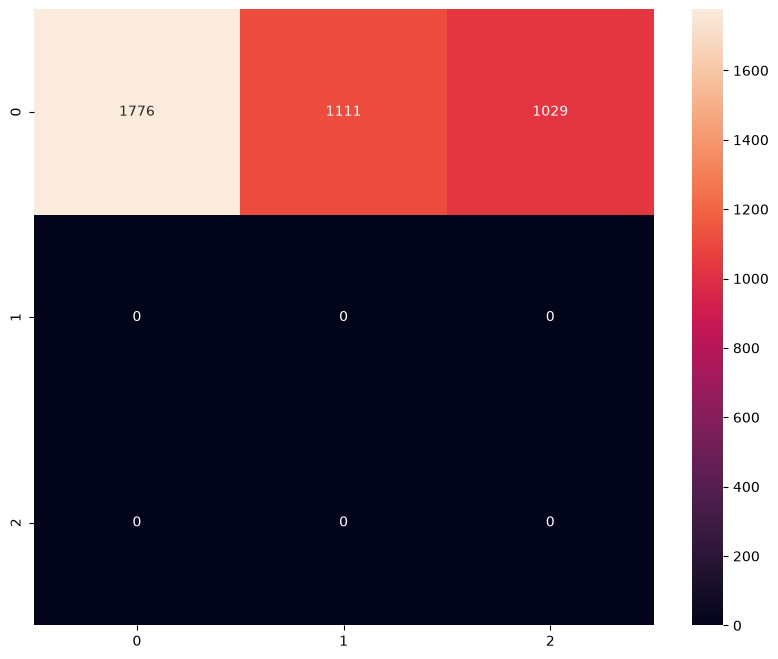

In [124]:
# Confusion matrix

plt.figure(figsize = (10,8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = 'd')
plt.show()

In [125]:
# Classification Report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.45      0.62      3916
           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         0

    accuracy                           0.45      3916
   macro avg       0.33      0.15      0.21      3916
weighted avg       1.00      0.45      0.62      3916



C:\Users\varsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\varsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\varsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
